In [93]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import uncertainties as unc
import uncertainties.unumpy as unp
from scipy.optimize import curve_fit
from uncertainties import ufloat

In [94]:
# Import data
data1 = pd.read_csv('./Exercise1.csv')
data2 = pd.read_csv('./Exercise2.csv')

# Uncertainties
timebase_acc = 100e-6
horizontal_div = 30e-6
data1_screen_width = 10 * horizontal_div
data1_unc = timebase_acc * data1['Response time (μs)'] / 1e6 + .0016 * data1_screen_width + 200e-12
data1_unc *= 1e6 # Convert to μs

Linear fit: y = (3.590±0.006)×10⁰ x + (-4.699±0.154)×10⁰
Chi2 = 34.15
Reduced chi2 = 0.88



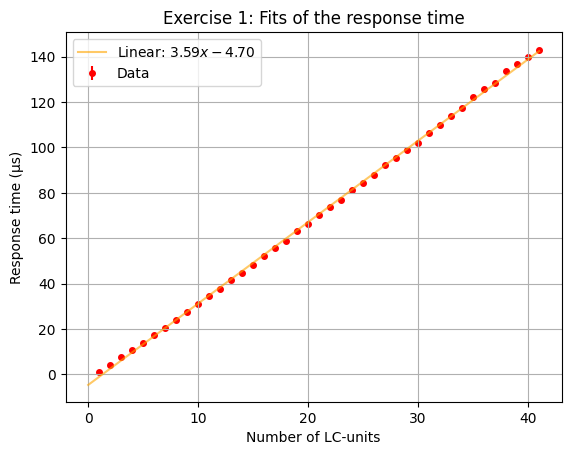

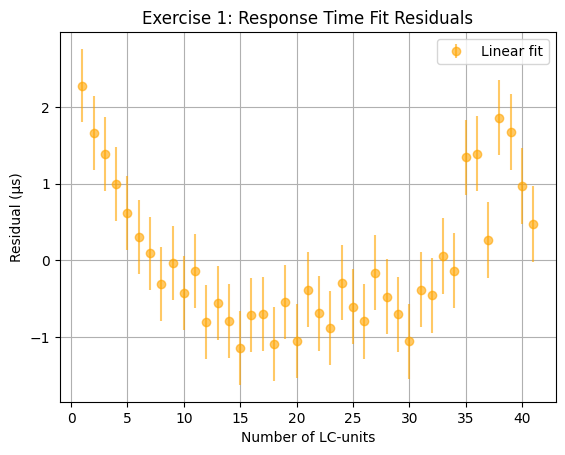

In [95]:
# Exercise 1: Determine the speed of pulse propagation along the line

# Given values
L0 = ufloat(1.5e-3, 1.5e-3 * 10/100) # Inductance of one LC-unit (H)
C0 = ufloat(0.01e-6, 0.01e-6 * 3/100) # Capacitance of one LC-unit (F)

# Theoretical speed of pulse propagation
v_theoretical = 1/unp.sqrt(L0*C0) # (2.582±0.135)×10⁵ LC-units/s

t = np.arange(0, 41, 1e-3)

# Fit a linear model to the response time
lin = lambda x, a, b: np.polyval([a, b], x)
popt, pcov = curve_fit(lin, data1['Number of LC-units'], data1['Response time (μs)'], sigma=data1_unc, absolute_sigma=True)
perr = np.sqrt(np.diag(pcov))
upopt = unp.uarray(popt, perr)
v_fit = 1e6/upopt[0]
lin_formula = 'y = {:.3eP} x + {:.3eP}'.format(*upopt)
lin_res = data1['Response time (μs)'] - lin(data1['Number of LC-units'], *popt)

# Calculate chi2 and reduced chi2
chi2 = np.sum(lin_res**2)
dof = len(data1['Number of LC-units']) - len(popt)
chi2_red = chi2/dof

# Print results
print(f'Linear fit: {lin_formula}')
print(f'Chi2 = {chi2:.2f}')
print(f'Reduced chi2 = {chi2_red:.2f}\n')

# Plot fit
plt.plot(t, lin(t, *popt), label='Linear: ${:.2f}x{:+.2f}$'.format(*popt), color='orange', alpha=.6)

# Plot the data
plt.errorbar(data1['Number of LC-units'], data1['Response time (μs)'], yerr=data1_unc, fmt='o', label='Data', zorder=0, color='red', markersize=4)
plt.xlabel('Number of LC-units')
plt.ylabel('Response time (μs)')
plt.legend()
plt.grid()
plt.title('Exercise 1: Fits of the response time')
plt.savefig('exercise1-time_fits.png')
plt.show()

# Plot the residuals
plt.errorbar(data1['Number of LC-units'], lin_res, yerr=data1_unc, fmt='o', label='Linear fit', color='orange', alpha=.6)
plt.xlabel('Number of LC-units')
plt.ylabel('Residual (μs)')
plt.legend()
plt.grid()
plt.title('Exercise 1: Response Time Fit Residuals')
plt.savefig('exercise1-time_residuals.png')
plt.show()

In [96]:
print(f'Theoretical speed of pulse propagation: {v_theoretical:.3eP} LC-units/s')
print(f'Fitted speed of pulse propagation: {v_fit:.3eP} LC-units/s\n')

Theoretical speed of pulse propagation: (2.582±0.135)×10⁵ LC-units/s
Fitted speed of pulse propagation: (2.785±0.005)×10⁵ LC-units/s



In [97]:
# Exercise 2: Comparing the pulse delay to the speed of light, Determining the attenuation factor & the characteristic impedance

# Given values
c = 299792458 # Speed of light in vacuum (m/s)
eps = 2.25 # Dielectric constant of the cable
mu = 1 # Permeability of the cable

# Theoretical speed of light in the cable
v_light = c/np.sqrt(eps*mu) # 2.0e8 m/s

